# Car Damage Detection

Six-class image classification (front / rear × normal, breakage, crushed) with PyTorch and transfer learning.

Project brief, dataset and baseline approach from the Codebasics course *Deep Learning: Beginner to
Advanced* (codebasics.io). This notebook is my own rebuild: the train-only augmentation, the seeded
stratified train / validation / test split, the best-epoch checkpoint and the test-set evaluation are mine.

The dataset is not included in this repository; Codebasics does not permit redistributing it. See the
README for how to obtain it.

---

# STEP 1: Requirements and Scope of Work (SOW)

> *Agree the problem before touching any data*

**Client:** VROOM Cars &nbsp;&middot;&nbsp; **Service Provider:** AtliQ Technologies

**Project:** a **Proof of Concept** for car damage detection. Classify the condition of a car's front and rear into
six predefined categories, delivered as a trained model inside a Streamlit app. The POC exists to judge whether an
automated damage-detection system is viable for VROOM Cars at all.

**Problem statement.** From an uploaded car image, predict one of:

| | Normal | Breakage | Crushed |
|---|---|---|---|
| **Front** | Front Normal | Front Breakage | Front Crushed |
| **Rear** | Rear Normal | Rear Breakage | Rear Crushed |

**Deliverables**

1. A trained model for car damage detection, with source code.
2. **Accuracy above 75%.**
3. A Streamlit app where a user drags and drops an image and sees the predicted class.

---

---

# STEP 2: Data Collection

> *Data discovery, access control*

The client's data is **2,300 labelled photos**, and the labels are the folder names:

| Folder | Class | Images |
|---|---|---|
| `F_Breakage` | Front Breakage | 500 |
| `F_Crushed` | Front Crushed | 400 |
| `F_Normal` | Front Normal | 500 |
| `R_Breakage` | Rear Breakage | 300 |
| `R_Crushed` | Rear Crushed | 300 |
| `R_Normal` | Rear Normal | 300 |

Two things to carry forward:

* **It is small.** 2,300 images across six classes is very little for a network to learn vision from scratch.
  That single fact explains the whole arc of Step 6.
* **It is mildly imbalanced.** 1,400 front images against 900 rear. Not severe, but a random split will not
  preserve it exactly, and per-class numbers in Step 7 need reading with the class sizes in mind.
---

In [4]:
import copy
import time
import optuna
import torch
import numpy as np
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.models as models
from matplotlib import pyplot as plt
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

---

# STEP 3: Data Cleaning, Transformation + STEP 5: Feature Engineering

> *Transform the raw data; create new features*

One `transforms.Compose` does the work of two ML life-cycle steps, and it is defined **before** the data is loaded
because `ImageFolder` runs it on every image at the moment the image is read.

| Line | Step | Why |
|---|---|---|
| `RandomHorizontalFlip()` | 5 - augmentation | A damaged left headlight and a damaged right headlight are the same class |
| `RandomRotation(10)` | 5 - augmentation | Photos are never perfectly level |
| `ColorJitter(brightness, contrast)` | 5 - augmentation | Lighting varies between yards, phones and weather |
| `Resize((224, 224))` | 3 - transformation | Every image must be the same shape; 224 is what ImageNet models expect |
| `ToTensor()` | 3 - transformation | PIL image to a `[3, 224, 224]` float tensor in the range 0 to 1 |
| `Normalize(mean, std)` | 3 - transformation | The ImageNet channel statistics, so pretrained weights see the input distribution they were trained on |

**Augmentation is the image version of feature engineering.** I am not adding columns; I am adding
*variation*, so that 2,300 photos behave like many more.

---

### Load Data

In [6]:
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize,
])

eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize,
])

---

# STEP 2: Data Collection (continued)

> *Load the images, then split*

---

In [7]:
SEED = 42
torch.manual_seed(SEED)

dataset_path = "../dataset"

base = datasets.ImageFolder(root=dataset_path)
len(base)

2300

In [8]:
class_names = base.classes
class_names

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [9]:
num_classes = len(class_names)
num_classes

6

In [10]:
indices = list(range(len(base)))

train_idx, holdout_idx = train_test_split(
    indices, test_size=0.30, stratify=base.targets, random_state=SEED
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, stratify=[base.targets[i] for i in holdout_idx], random_state=SEED
)

len(train_idx), len(val_idx), len(test_idx)

(1610, 345, 345)

In [11]:
train_dataset = Subset(datasets.ImageFolder(root=dataset_path, transform=train_transforms), train_idx)
val_dataset = Subset(datasets.ImageFolder(root=dataset_path, transform=eval_transforms), val_idx)
test_dataset = Subset(datasets.ImageFolder(root=dataset_path, transform=eval_transforms), test_idx)

In [12]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(len(train_dataset), len(val_dataset), len(test_dataset))
print("per class in test:", np.bincount([base.targets[i] for i in test_idx]))

1610 345 345
per class in test: [75 60 75 45 45 45]


---

# STEP 4: Exploratory Data Analysis

> *Understand what the model will actually see*

---

In [18]:
for images, labels in train_loader:
    print(images.shape)
    print(labels.shape)
    break

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [19]:
labels[1]

tensor(0)

In [20]:
images[1].shape

torch.Size([3, 224, 224])

In [21]:
images[1].permute(1,2,0).shape

torch.Size([224, 224, 3])

In [ ]:
plt.imshow(images[1].permute(1,2,0))
plt.show()

---

# STEP 6: Model Selection and Training

> *Pick the correct architecture and train it*

---

### Model 1: CNN

In [29]:
class CarClassifierCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # (16, 224, 224)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (16, 112, 112)
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), # (32, 112, 112)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (32, 56, 56)
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), # (64, 56, 56)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (64, 28, 28)
            nn.Flatten(),
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.network(x)
        return x

In [30]:
images.size(0)

32

In [31]:
len(train_loader.dataset)

1610

In [13]:
def evaluate(model, loader):
    model.eval()
    all_labels, all_predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_predictions)

def train_model(model, criterion, optimizer, epochs=5):
    start = time.time()
    best_accuracy, best_state = -1.0, None

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)
        labels, predictions = evaluate(model, val_loader)
        accuracy = 100 * (labels == predictions).mean()
        print(f"Epoch [{epoch+1}/{epochs}] loss {epoch_loss:.4f} val accuracy {accuracy:.2f}%")

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    print(f"Best val accuracy {best_accuracy:.2f}% ({time.time() - start:.0f}s)")
    return best_accuracy

In [40]:
# Instantiate the model, loss function, and optimizer
model = CarClassifierCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_model(model, criterion, optimizer, epochs=10)

Epoch [1/10] loss 2.0050 val accuracy 33.33%
Epoch [2/10] loss 1.5448 val accuracy 39.13%
Epoch [3/10] loss 1.3056 val accuracy 45.22%
Epoch [4/10] loss 1.2236 val accuracy 48.41%
Epoch [5/10] loss 1.1325 val accuracy 52.46%
Epoch [6/10] loss 1.0641 val accuracy 52.75%
Epoch [7/10] loss 0.9432 val accuracy 52.75%
Epoch [8/10] loss 0.9105 val accuracy 53.33%
Epoch [9/10] loss 0.8187 val accuracy 56.23%
Epoch [10/10] loss 0.7512 val accuracy 56.81%
Best val accuracy 56.81% (794s)


np.float64(56.811594202898554)

### Model 2: CNN with Regularization

In [41]:
class CarClassifierCNNWithRegularization(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1), # (16, 224, 224) 
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (16, 112, 112),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (32, 56, 56)           
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2, padding=0), # (64, 28, 28),
            nn.Flatten(),
            nn.Linear(64*28*28, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
        
    def forward(self, x):
        x = self.network(x)
        return x

In [42]:
model = CarClassifierCNNWithRegularization(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

train_model(model, criterion, optimizer,  epochs=10)

Epoch [1/10] loss 7.9712 val accuracy 36.52%
Epoch [2/10] loss 1.4096 val accuracy 48.99%
Epoch [3/10] loss 1.2670 val accuracy 49.28%
Epoch [4/10] loss 1.2264 val accuracy 55.07%
Epoch [5/10] loss 1.1815 val accuracy 54.49%
Epoch [6/10] loss 1.1671 val accuracy 52.17%
Epoch [7/10] loss 1.1525 val accuracy 47.83%
Epoch [8/10] loss 1.1454 val accuracy 51.30%
Epoch [9/10] loss 1.0951 val accuracy 57.68%
Epoch [10/10] loss 1.0711 val accuracy 55.07%
Best val accuracy 57.68% (887s)


np.float64(57.68115942028985)

### Model 3: Transfer Learning with EfficientNet

In [47]:
model = models.efficientnet_b0(weights='DEFAULT')
model.classifier[1].in_features

1280

In [52]:
class CarClassifierEfficientNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.efficientnet_b0(weights='DEFAULT')

        for param in self.model.parameters():
            param.requires_grad = False

        in_features = self.model.classifier[1].in_features

        self.model.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(in_features, num_classes)
        )
        
    def forward(self, x):
        x = self.model(x)
        return x

In [53]:
model = CarClassifierEfficientNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

train_model(model, criterion, optimizer, epochs=10)

Epoch [1/10] loss 1.4726 val accuracy 58.26%
Epoch [2/10] loss 1.1476 val accuracy 60.87%
Epoch [3/10] loss 1.0198 val accuracy 64.93%
Epoch [4/10] loss 0.9506 val accuracy 64.35%
Epoch [5/10] loss 0.9172 val accuracy 64.06%
Epoch [6/10] loss 0.8940 val accuracy 65.51%
Epoch [7/10] loss 0.8562 val accuracy 66.09%
Epoch [8/10] loss 0.8277 val accuracy 64.06%
Epoch [9/10] loss 0.7871 val accuracy 64.93%
Epoch [10/10] loss 0.8014 val accuracy 64.64%
Best val accuracy 66.09% (1035s)


np.float64(66.08695652173913)

### Model 4: Transfer Learning with ResNet

In [14]:
# Load the pre-trained ResNet model
class CarClassifierResNet(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5):
       super().__init__()
       self.model = models.resnet50(weights='DEFAULT')
       # Freeze all layers except the final fully connected layer
       for param in self.model.parameters():
           param.requires_grad = False
           
       # Unfreeze layer 4 and fc layers
       for param in self.model.layer4.parameters():
           param.requires_grad = True

       # Replace the final fully connected layer
       self.model.fc = nn.Sequential(
           nn.Dropout(dropout_rate),
           nn.Linear(self.model.fc.in_features, num_classes)
       )

    def forward(self, x):
        x = self.model(x)
        return x

In [64]:
model = CarClassifierResNet(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p:p.requires_grad, model.parameters()), lr=0.001)

train_model(model, criterion, optimizer, epochs=10)

Epoch [1/10] loss 0.8966 val accuracy 70.14%
Epoch [2/10] loss 0.4731 val accuracy 76.81%
Epoch [3/10] loss 0.3978 val accuracy 74.78%
Epoch [4/10] loss 0.2623 val accuracy 76.81%
Epoch [5/10] loss 0.2122 val accuracy 80.00%
Epoch [6/10] loss 0.2081 val accuracy 75.65%
Epoch [7/10] loss 0.1319 val accuracy 80.87%
Epoch [8/10] loss 0.1234 val accuracy 81.45%
Epoch [9/10] loss 0.1157 val accuracy 75.65%
Epoch [10/10] loss 0.0845 val accuracy 83.19%
Best val accuracy 83.19% (2068s)


np.float64(83.18840579710145)

---

# STEP 8: Model Fine Tuning

> *Search the hyperparameters with Optuna*

**What is searched**

| Hyperparameter | Range | Sampling |
|---|---|---|
| `lr` | 1e-5 to 1e-2 | log scale, because learning rates matter by order of magnitude |
| `dropout_rate` | 0.2 to 0.7 | uniform |

**How the cost is kept down.** Each trial trains for **3 epochs**, not 10, and reports its validation accuracy
after every epoch. Optuna's pruner stops a trial early if it is clearly behind the others
(`trial.should_prune()`).

---

### Model Training & Hyperparameter Tuning

In [73]:
# Define the objective function for Optuna
def objective(trial):
    # Suggest values for the hyperparameters
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)
    dropout_rate = trial.suggest_float('dropout_rate', 0.2, 0.7)
    
    # Load the model
    model = CarClassifierResNet(num_classes=num_classes, dropout_rate=dropout_rate).to(device)

    # Define the loss function and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)

    # Training loop
    epochs = 3
    start = time.time()
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for batch_num, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)

        # Validation loop
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total
        
        # Report intermediate result to Optuna
        trial.report(accuracy, epoch)
        
        # Handle pruning
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()
            
    end = time.time()
    print(f"Execution time: {end - start} seconds")
    
    return accuracy

In [74]:
# Create the study and optimize
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=20)

[I 2026-10-13 00:56:07,742] A new study created in memory with name: no-name-0ee27199-d691-41e4-a56d-eb93d698adca
[I 2026-10-13 01:06:36,721] Trial 0 finished with value: 73.91304347826087 and parameters: {'lr': 0.0001329291894316216, 'dropout_rate': 0.675357153204958}. Best is trial 0 with value: 73.91304347826087.


Execution time: 628.643563747406 seconds


[I 2026-10-13 01:17:09,075] Trial 1 finished with value: 80.8695652173913 and parameters: {'lr': 0.001570297088405539, 'dropout_rate': 0.49932924209851826}. Best is trial 1 with value: 80.8695652173913.


Execution time: 632.013432264328 seconds


[I 2026-10-13 01:27:51,216] Trial 2 finished with value: 68.98550724637681 and parameters: {'lr': 2.9380279387035334e-05, 'dropout_rate': 0.27799726016810133}. Best is trial 1 with value: 80.8695652173913.


...

[I 2026-10-13 02:55:41,054] Trial 13 finished with value: 82.31884057971014 and parameters: {'lr': 0.0012211904081168077, 'dropout_rate': 0.3875236904253685}. Best is trial 13 with value: 82.31884057971014.


Execution time: 630.6043198108673 seconds


[I 2026-10-13 03:02:39,363] Trial 14 pruned. 
[I 2026-10-13 03:13:15,979] Trial 15 finished with value: 80.28985507246377 and parameters: {'lr': 0.0018244007129661287, 'dropout_rate': 0.20587663687268076}. Best is trial 13 with value: 82.31884057971014.


Execution time: 636.2378106117249 seconds


[I 2026-10-13 03:16:50,307] Trial 16 pruned. 
[I 2026-10-13 03:20:22,041] Trial 17 pruned. 
[I 2026-10-13 03:27:19,855] Trial 18 pruned. 
[I 2026-10-13 03:30:53,251] Trial 19 pruned. 


In [75]:
study.best_params

{'lr': 0.0012211904081168077, 'dropout_rate': 0.3875236904253685}

---

# STEP 6: Model Selection & Training (revisited)

> *Retrain the chosen model with the tuned settings*

---

The final retrain and evaluation were re-run in a second session after a kernel restart, using the
parameters the search above printed.

In [16]:
# best = study.best_params
best = {'lr': 0.0012211904081168077, 'dropout_rate': 0.3875236904253685}

model = CarClassifierResNet(num_classes=num_classes, dropout_rate=best['dropout_rate']).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=best['lr'])

train_model(model, criterion, optimizer, epochs=10)

Epoch [1/10] loss 0.8816 val accuracy 73.91%
Epoch [2/10] loss 0.5020 val accuracy 75.07%
Epoch [3/10] loss 0.3654 val accuracy 79.42%
Epoch [4/10] loss 0.2528 val accuracy 80.87%
Epoch [5/10] loss 0.1770 val accuracy 80.00%
Epoch [6/10] loss 0.1516 val accuracy 81.16%
Epoch [7/10] loss 0.1776 val accuracy 84.64%
Epoch [8/10] loss 0.1311 val accuracy 82.90%
Epoch [9/10] loss 0.1107 val accuracy 81.16%
Epoch [10/10] loss 0.0740 val accuracy 82.90%
Best val accuracy 84.64% (2200s)


np.float64(84.63768115942028)

---

# STEP 7: Model Evaluation

> *Evaluate the model using relevant metrics*

---

Test accuracy: 80.29%
              precision    recall  f1-score   support

  F_Breakage       0.87      0.88      0.87        75
   F_Crushed       0.85      0.57      0.68        60
    F_Normal       0.76      0.97      0.85        75
  R_Breakage       0.82      0.80      0.81        45
   R_Crushed       0.71      0.64      0.67        45
    R_Normal       0.81      0.87      0.84        45

    accuracy                           0.80       345
   macro avg       0.80      0.79      0.79       345
weighted avg       0.81      0.80      0.80       345



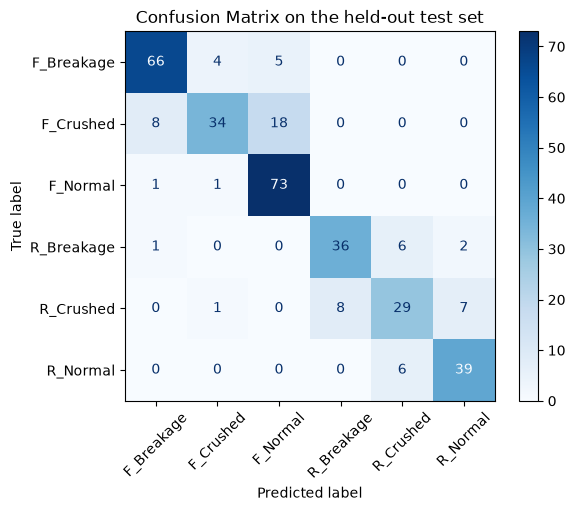

In [17]:
labels, predictions = evaluate(model, test_loader)
print(f"Test accuracy: {100 * (labels == predictions).mean():.2f}%")
print(classification_report(labels, predictions, labels=np.arange(num_classes), target_names=class_names, zero_division=0))

conf_matrix = confusion_matrix(labels, predictions, labels=np.arange(num_classes))
ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names).plot(
 cmap=plt.cm.Blues, xticks_rotation=45
)
plt.title('Confusion Matrix on the held-out test set')
plt.show()

In [18]:
normal_ids = [i for i, name in enumerate(class_names) if name.endswith("Normal")]
is_damaged = ~np.isin(labels, normal_ids)
called_damaged = ~np.isin(predictions, normal_ids)
caught = (is_damaged & called_damaged).sum()
print(f"Damaged cars caught: {caught} of {is_damaged.sum()} (recall {caught / is_damaged.sum():.1%})")

Damaged cars caught: 193 of 225 (recall 85.8%)


---

# STEP 9: Model Deployment

> *Deploy it in a production environment*

---

### Save the Model

In [19]:
torch.save(model.state_dict(), "../artifacts/saved_model.pth")

---

# STEP 10: Monitoring & Feedback Loop

> *Monitor the model's performance and update it as required*

**What to monitor**

* **Confidence distribution.** Log the top-class probability of every prediction. A drift towards low-confidence
  predictions is the earliest sign that incoming photos no longer look like the training photos.
* **Input drift I can measure cheaply.** Image resolution, aspect ratio, brightness, the share of night or
  indoor shots. A new phone model or a new inspection bay changes all of these.
* **Human disagreement.** Wherever an assessor overrides the model, I will keep the image and the corrected label. That
  is both the accuracy measure and the retraining set.

**The feedback loop**

| Trigger | Response |
|---|---|
| Confidence or input statistics drift | Sample and label recent images; measure accuracy on them before deciding anything |
| Accuracy on fresh labelled images falls under the SOW's 75% | Retrain with the new images added; re-check the per-class numbers from Step 7 |
| A cluster of overrides on one class pair | Review the labelling guideline for that pair. Breakage versus crushed is a judgement call, and the fix may be the labels, not the model |

**The limit worth stating plainly.** 2,300 images from one source is enough to show the idea works. It is not
enough to trust on photos taken anywhere else, and no number in this notebook measures that.

---

---

<div align="center">

### End of Project 3

</div>